# 1-board: current-scale

Measure the current chain's scale in counts per amp and its zero under drive against the meter, so the firmware's amperes rest on a graded number and not on a parts list.

## Purpose

The firmware limits, trips, identifies and estimates in amperes, and every one of those amperes is one ADC count through the shunt and its amplifier. The board registry carries the parts' nominal values, a 60 mOhm shunt and a gain of 14.884, which give a nominal 1108.5 counts per amp. The shunt is a 1 % metal alloy part, a JIERR JER1206F1R060 rated 50 ppm per C, and the gain is set by two resistors, so the nominal is a starting point. This experiment grades it against the meter on DC, where the bridge does not switch and nothing but the chain can disagree with the meter, and finds the zero the chain reads under drive, which the torque-off rest does not show. Two loads cover two current ranges, and whether one line fits both is part of what gets settled.

The chain's op-amp was characterized once on an earlier board, and this experiment leans on that rather than repeating it. It runs in its normal mode, with the high-speed mode off. Its gain moves about a quarter of a percent over 30 C of board. And the chain carries a fixed offset of some ten counts that is there only while the bridge drives. The gain read per level is the counts over the zero divided by the amps, and a fixed offset makes it fall as the current rises. So this experiment fits one line with an intercept, reports the scale, the zero and the in-drive offset with their errors, and leaves the op-amp alone.

## Procedure

`capture.py` runs one pass per argument, `bare` or `series`. Each pass is a set of DC laps on one load. A lap is one `osc sweep` at a supply level: a one second torque-off rest, then 100 % duty for three seconds in one direction, a two second rest, and three seconds in the other direction. At 100 % duty the bridge holds one leg high and one low for the whole lap, so there is no switching, the current is DC, and the chip's shunt amplifier and a meter in series with the load read the same current. The three second lap is the longest burst the servo arms. The script writes a current limit of 2000 counts for the pass and puts the saved value back after. The experiment image accepts that register and ignores it, so the raw current trip is the only current protection under a lap.

1. The board on the DPS, the adapter on the bus at 3 Mbps. The board runs the experiment image, so the laps are open loop with only the raw current trip and the bus dead-man as protections.
2. The DMM on DC A, the red probe in the A jack, which is the 20 A range on the B41T+. The loop is MOT_A to the meter, the meter to the load, the load to MOT_B. The meter's Bluetooth log runs through the pass and the script refuses to start if the dial is on another function.
3. `capture.py bare`. The DPS comes on before the board's leads go on, because its output comes up at its previous setting for a moment. The script then trims the DPS until the board's own rail tap reads each level, 3.3, 3.7, 4.2, 4.5, 5.0, 5.5, 7.2 and 7.6 V, and records one lap per level. The bare 5 ohm load stops at 7.6 V to stay under its 12 W.
4. `capture.py series` with the 15 ohm series load, the same levels plus 8.0 V.
5. `capture.py rs1` with the bare load alone across the terminals and the meter on DC millivolts, in manual range, across a twisted pair soldered to the shunt pads.

The levels name the rail, VSYS. A swap board has no feed diode and its rail is the battery, so the DPS is trimmed over the dev board's diode until the rail reads the level. The trim reads the rail through the chip's own 1.2 V reference, so a regulator in dropout does not fool it.

The third pass, `rs1`, takes the shunt's own value out of the route and grades the amplifier and the ADC alone, on the meter's millivolt range rather than its 20 A jack. Board D had no pads when the first two passes ran, so the pair was soldered on afterwards and the pass run with the other two in hand.

## Data

Three folders under the capture, `bare`, `series` and `rs1`, with the same layout.

- `levels.csv`: one row per lap. `k` the lap number, `load`, `volts_set` the rail level asked for, `dps_read` the DPS output that reached it, `vsys_read` the rail the board read at rest before the lap, `t_start` and `t_end` the host time the sweep ran, `folder` the lap's folder.
- `dmm.csv`: the meter's log through the pass. `t_host`, `function` (`DC A`, or `DC V` in `rs1`), `value` in amps or in volts across the shunt, `raw` the packet.
- `laps/<k>/sweep.csv`, `meta.json`: the rest and the two laps at that level, one row per control tick at 20 kHz. Segment 0 is the rest, 1 and 2 the two directions. `current_raw`, `vmotor_a`, `vmotor_b`, `vbus_raw` and `ntc_raw` are ADC counts. `vref_raw` is in the header but empty, the lap's telemetry chunk does not carry it.

### levels.csv

The rail asked for and the rail read, per lap, both passes.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oscnb import b41t, boards, laps, results, tel
from oscnb.display import show

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#898781"   # the house colours
COLOR = {"bare": BLUE, "series": ORANGE}                                # one colour per load, fixed through the notebook
BOARD = boards.BOARDS[boards.DEFAULT]                                   # the board, with the parts' nominal values
CAPTURE = (Path("../../../telemetry") / BOARD.key / "current-scale" / "capture-1").resolve()
PASSES = ["bare", "series"]
print(BOARD.key, "from", results.rel(CAPTURE))
print(f"nominal chain: {BOARD.shunt_mohm} mOhm x gain {BOARD.gain_milli / 1e3:.3f} on a {BOARD.vdd_mv / 1e3:.1f} V reference = {BOARD.counts_per_a:.1f} counts per amp")
print(f"op-amp input pull-ups: {BOARD.opa_pullup_ohm} ohm to the {BOARD.vdd_mv / 1e3:.1f} V rail on both inputs")

dev-v006-2A-D from telemetry/dev-v006-2A-D/current-scale/capture-1
nominal chain: 60 mOhm x gain 14.884 on a 3.3 V reference = 1108.5 counts per amp
op-amp input pull-ups: 1500 ohm to the 3.3 V rail on both inputs


,pass_,k,load,volts_set,dps_read,vsys_read,trim_mv,t_start,t_end,folder
0,bare,0,bare,3.300,3.550,3.282,-18.000,1793053675.148,1793053686.435,laps/0
1,bare,1,bare,3.700,3.950,3.679,-21.000,1793053690.369,1793053701.718,laps/1
2,bare,2,bare,4.200,4.450,4.190,-10.000,1793053705.649,1793053717.026,laps/2
3,bare,3,bare,4.500,4.750,4.484,-16.000,1793053720.959,1793053732.365,laps/3
4,bare,4,bare,5.000,5.250,4.974,-26.000,1793053736.296,1793053747.681,laps/4
5,bare,5,bare,5.500,5.750,5.477,-23.000,1793053751.612,1793053762.969,laps/5
6,bare,6,bare,7.200,7.450,7.172,-28.000,1793053766.898,1793053778.245,laps/6
7,bare,7,bare,7.600,7.888,7.616,16.000,1793053786.107,1793053797.422,laps/7
8,series,0,series,3.300,3.550,3.271,-29.000,1793054304.473,1793054315.765,laps/0
9,series,1,series,3.700,3.950,3.688,-12.000,1793054319.745,1793054331.058,laps/1


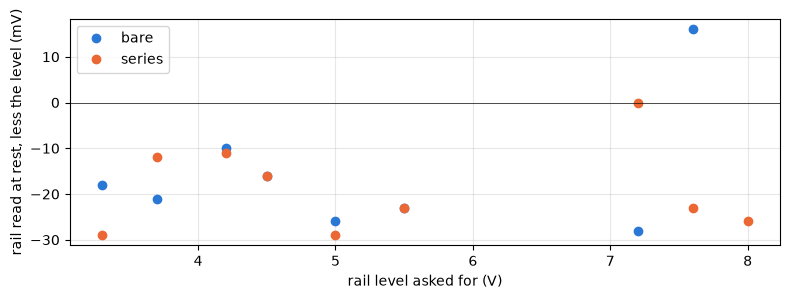

In [2]:
# every lap of both passes in one table, with the pass name as a column
levels = pd.concat([pd.read_csv(CAPTURE / p / "levels.csv").assign(pass_=p) for p in PASSES], ignore_index=True)
levels["trim_mv"] = (levels["vsys_read"] - levels["volts_set"]) * 1e3   # how far the trim landed from the level
show(levels[["pass_", "k", "load", "volts_set", "dps_read", "vsys_read", "trim_mv", "t_start", "t_end", "folder"]], n=None)
fig, ax = plt.subplots(figsize=(8, 3))
for p in PASSES:
    g = levels[levels["pass_"] == p]
    ax.plot(g["volts_set"], g["trim_mv"], "o", color=COLOR[p], label=p)   # one dot per lap
ax.axhline(0, color=INK, lw=0.5)
ax.set_xlabel("rail level asked for (V)"); ax.set_ylabel("rail read at rest, less the level (mV)")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

How far the trim landed from each level. Every lap sits within 30 mV of its level, so the levels can be read as the rails they name.

### dmm.csv

The meter's log through each pass, with each lap's sweep shaded. Inside a sweep the meter reads zero in the rests and the lap current in each direction, positive one way and negative the other.

bare packets: 253 functions: ['DC A'] range byte: ['a3f0']
series packets: 282 functions: ['DC A'] range byte: ['a3f0']


,t_host,function,value,raw,t
0,15:27:51.367,DC A,0.000,a3f000000000,0.000
1,15:27:51.951,DC A,0.000,a3f000000000,0.585
2,15:27:52.342,DC A,0.000,a3f000000000,0.975
3,15:27:52.927,DC A,0.000,a3f000000000,1.561
4,15:27:53.318,DC A,0.000,a3f000000000,1.951


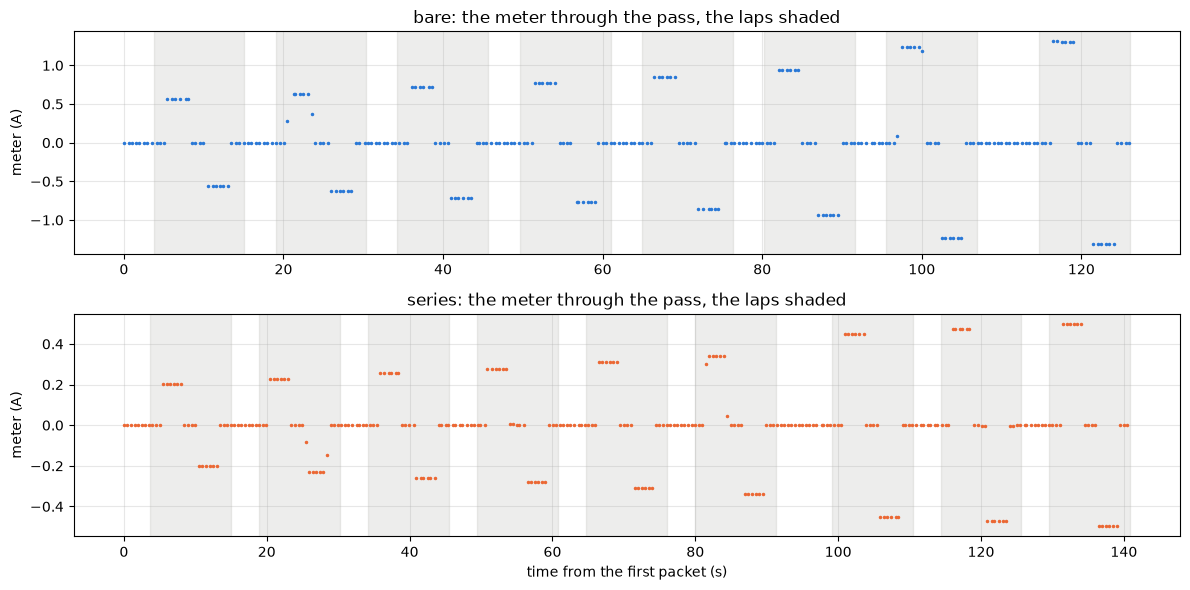

In [3]:
dmm = {p: b41t.load(CAPTURE / p / "dmm.csv") for p in PASSES}   # one frame per pass: t_host, function, value, raw
for p in PASSES:
    print(p, "packets:", len(dmm[p]), "functions:", dmm[p]["function"].unique().tolist(), "range byte:", dmm[p]["raw"].str[:4].unique().tolist())
show(dmm["bare"])
fig, ax = plt.subplots(2, 1, figsize=(12, 6))
for a, p in zip(ax, PASSES):
    d = dmm[p]
    a.plot(d["t"], d["value"], ".", ms=3, color=COLOR[p])                  # every packet
    for _, L in levels[levels["pass_"] == p].iterrows():                  # shade each lap's sweep window
        a.axvspan(L["t_start"] - d["t_host"].iloc[0], L["t_end"] - d["t_host"].iloc[0], color=MUTED, alpha=0.15)
    a.set_ylabel("meter (A)"); a.set_title(f"{p}: the meter through the pass, the laps shaded"); a.grid(alpha=0.3)
ax[-1].set_xlabel("time from the first packet (s)")
plt.tight_layout(); plt.show()

The meter reads a staircase of levels in each pass, each lap a positive stretch and a negative one of about six packets. The range byte of every packet is the same, so the meter stayed on one range through both passes.

### laps/K/sweep.csv and meta.json

One lap, the 7.6 V level of the bare pass. The current channel, the two terminal taps and the rail tap over the rest and the two directions.

segments: {0: 20000, 1: 60000, 2: 60000} | schedule: ['100@3000'] | baseline ms: 1000 | rest ms: 2000 | decay: slow


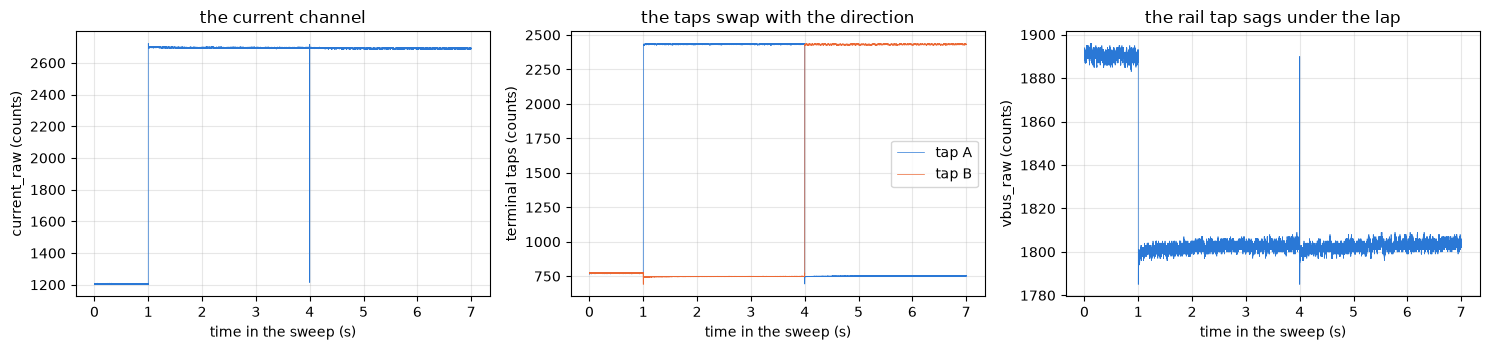

missing rows per lap: {'bare': {0: 0, 1: 0, 2: 0, 3: 0, 4: 0, 5: 0, 6: 0, 7: 0}, 'series': {0: 0, 1: 0, 2: 0, 3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0}}


In [4]:
def lap_folder(p, k):
    return CAPTURE / p / levels[(levels["pass_"] == p) & (levels["k"] == k)]["folder"].iloc[0]

df, meta = tel.load(lap_folder("bare", 7), BOARD)     # checks the sense block against the board entry
print("segments:", df["seg"].value_counts().sort_index().to_dict(), "| schedule:", meta["schedule"],
      "| baseline ms:", meta["baseline_ms"], "| rest ms:", meta["rest_ms"], "| decay:", meta["decay"])
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ts = np.arange(len(df)) / meta["tick_hz"]                 # time through the sweep; `t` restarts at each segment
ax[0].plot(ts, df["current_raw"], lw=0.5, color=BLUE); ax[0].set_ylabel("current_raw (counts)")
ax[1].plot(ts, df["vmotor_a"], lw=0.5, color=BLUE, label="tap A"); ax[1].plot(ts, df["vmotor_b"], lw=0.5, color=ORANGE, label="tap B")
ax[1].set_ylabel("terminal taps (counts)"); ax[1].legend()
ax[2].plot(ts, df["vbus_raw"], lw=0.5, color=BLUE); ax[2].set_ylabel("vbus_raw (counts)")
for a in ax:
    a.set_xlabel("time in the sweep (s)"); a.grid(alpha=0.3)
ax[0].set_title("the current channel"); ax[1].set_title("the taps swap with the direction"); ax[2].set_title("the rail tap sags under the lap")
plt.tight_layout(); plt.show()
missing = {p: {int(L["k"]): int(tel.gaps(tel.load(CAPTURE / p / L["folder"])[0]).sum()) for _, L in levels[levels["pass_"] == p].iterrows()} for p in PASSES}
print("missing rows per lap:", missing)

The rest at the zero, then the lap each way. The current channel reads the same current in both directions, since the shunt sits in the bridge's common return, and the taps swap. The rail tap drops under the lap by what the diode and the DPS leads lose at 1.3 A. No lap of either pass dropped a row.

## Raw traces

Every lap's current channel over time, one panel per pass, so the levels can be seen as a staircase and the rests compared across levels.

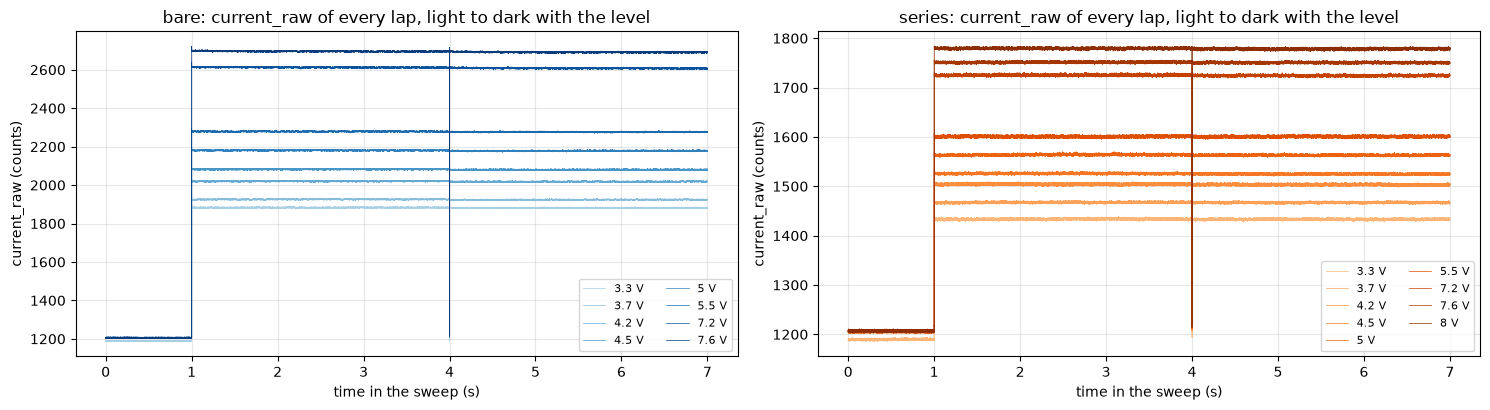

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
for a, p in zip(ax, PASSES):
    g = levels[levels["pass_"] == p]
    shades = (plt.cm.Blues if p == "bare" else plt.cm.Oranges)(np.linspace(0.35, 0.95, len(g)))   # one hue per load, light to dark with the level
    for shade, (_, L) in zip(shades, g.iterrows()):
        d, _ = tel.load(CAPTURE / p / L["folder"])
        a.plot(np.arange(len(d)) / BOARD.tick_hz, d["current_raw"], lw=0.5, color=shade, label=f"{L['volts_set']:g} V")
    a.set_title(f"{p}: current_raw of every lap, light to dark with the level"); a.set_xlabel("time in the sweep (s)")
    a.set_ylabel("current_raw (counts)"); a.legend(fontsize=8, ncol=2); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

The laps step up with the level in both passes. The 3.3 V lap of each pass, the lightest trace, rests about 16 counts under the others, which is the first sign that the 3.3 V level is not like the rest. Everything else sits where a staircase puts it.

## Method

Each lap gives two points, one per direction. The chip's reading is the mean of `current_raw` over the settled part of the lap, which leaves out the first 2 ms after the drive opens, less the lap's own rest zero, the median of `current_raw` over the second half of the one second torque-off rest. The meter's reading is the median of its packets in the driven stretch that direction made in the log. The log is not on the sweep's clock, so the stretches are found in the log itself, as runs of readings well away from zero, split where the sign flips, in the order the sweep drives them. The meter's lag from the dmm experiment is 20 ms with a spread under 200 ms, which is small against a three second lap, and the stretch's median is not moved by one packet caught on an edge.

The model is one line with an intercept,

$$n = b + G \, I$$

where $n$ is the counts over the lap's own zero, $I$ the meter's amps, $G$ the scale in counts per amp and $b$ the in-drive offset in counts, the offset that is there only while the bridge drives. The gain read per level, $n / I$, is then $G + b / I$, and falls as the current rises. A fit of a short current range with its own intercept trades $G$ against $b$, so the first test of the two loads is whether one free line fits every point of both passes to the noise, a few counts. If it does, the chain is linear with an offset, and the per-pass slopes are the short ranges talking. $G$ and $b$ are fitted by least squares with their standard errors, over both passes together, over each pass alone, and over each direction alone, and $G$ is compared with the registry's nominal.

Beyond the line, four things are looked at.

1. The lap's own zero against the level, and against VDD at that level, which is the ADC's reference. Board D carries two 1.5 kohm pull-ups from the 3V3 rail to the op-amp's inputs, in the registry entry as `opa_pullup_ohm`, hand-soldered parts rather than footprint parts, which lift the inputs' common mode and tie the torque-off zero to that rail.
2. The residuals from the common line against the current, the rail, the direction and the board temperature, and inside a lap, the drift of the chip's reading over the three seconds against the drift of the meter's own packets, which is where the shunt's self-heating and the amplifier's settle would show.
3. The direction, forward against reverse at the same level.
4. The terminal taps under load, as a second reference beside the meter. The tap difference over the load's stage 0 value is a current with no part of the current chain in it.

Stage 0 gives the loads' values and the leads, read from the result files below. The stage 1 rest-noise result gives the current channel's floor at rest, about one count rms, which is the least a lap's mean can scatter by.

### Stage 0 and rest-noise values carried in

In [6]:
PR = results.read("0-instruments", "power-resistors")            # the loads' cold values and the leads + ammeter
DMM = results.read("0-instruments", "dmm")                        # the meter's lag and its class on the 20 A range
RN = results.read("1-board", "rest-noise", pair=BOARD.key)        # the current channel's floor at rest and VDD from 3.7 V up
R_LOAD = {p: PR[p]["r_cold"]["value"] for p in PASSES}            # ohm, including each load's pigtails
R_LEADS = PR["leads"]["value"]                                    # ohm, the DPS leads and the ammeter at 1 A
for p in PASSES:
    q = PR[p]["r_cold"]
    print(f"{p:6s} load {q['value']:.3f} ohm ({q['lo']:.3f} to {q['hi']:.3f}), drift {PR[p]['drift']['value'] * 1e3:.2f} mOhm/W, up to {PR[p]['power_max']['value']:.1f} W")
print(f"leads + ammeter {R_LEADS:.3f} ohm ({PR['leads']['lo']:.3f} to {PR['leads']['hi']:.3f})")
print(f"meter lag {DMM['lag_s']['value'] * 1e3:.0f} ms ({DMM['lag_s']['lo'] * 1e3:.0f} to {DMM['lag_s']['hi'] * 1e3:.0f}); "
      f"class on the 20 A range {DMM['accuracy']['dc_a_20a']['pct']['value']} % + {DMM['accuracy']['dc_a_20a']['fixed']['value'] * 1e3:.0f} mA")
print(f"current channel at rest {RN['current_noise']['value']:.2f} counts rms; VDD {RN['vdd_v']['value']:.3f} V ({RN['vdd_v']['lo']:.3f} to {RN['vdd_v']['hi']:.3f}) over 3.7 to 7.4 V rails")

bare   load 5.092 ohm (5.089 to 5.094), drift 1.87 mOhm/W, up to 11.8 W
series load 15.269 ohm (15.258 to 15.280), drift 0.97 mOhm/W, up to 20.8 W
leads + ammeter 0.144 ohm (0.141 to 0.145)
meter lag 20 ms (-81 to 202); class on the 20 A range 2.0 % + 25 mA
current channel at rest 1.08 counts rms; VDD 3.292 V (3.287 to 3.297) over 3.7 to 7.4 V rails


### The lap table

One row per lap and direction, the meter joined by its driven stretches.

In [7]:
tables = {}
for p in PASSES:
    t = laps.table(CAPTURE / p, BOARD, dmm[p])        # the settled means, the rest zero, the meter's median per direction
    t["counts"] = t["current_raw"] - t["zero"]        # n, counts over the lap's own rest zero
    t["amps"] = t["meter"].abs()                      # I, the meter's current, unsigned
    tables[p] = t.assign(pass_=p)
T = pd.concat(tables.values(), ignore_index=True)
T["rail_v"] = T["vbus_raw"] * BOARD.v_rail_per_count                                   # the rail tap under the lap, at the nominal VDD
T["tap_v"] = (T["vmotor_a"] - T["vmotor_b"]).abs() * BOARD.v_term_per_count            # the terminal to terminal volts, bias free
T["gain_per_level"] = T["counts"] / T["amps"]                                          # n / I, the gain read per level
show(T[["pass_", "k", "volts_set", "dir", "zero", "current_raw", "counts", "current_sd", "n", "meter", "meter_n", "gain_per_level", "rail_v", "tap_v", "ntc_raw"]], n=None)
print(f"{len(T)} points, meter packets per point {T['meter_n'].min()} to {T['meter_n'].max()}, {T['amps'].min():.3f} to {T['amps'].max():.3f} A")

,pass_,k,volts_set,dir,zero,current_raw,counts,current_sd,n,meter,meter_n,gain_per_level,rail_v,tap_v,ntc_raw
0,bare,0,3.300,1,1189.000,1883.030,694.030,1.232,59960.000,0.559,6,1241.556,3.470,3.255,1966.919
1,bare,0,3.300,-1,1189.000,1881.344,692.344,1.242,59960.000,-0.559,6,1238.541,3.470,3.247,1966.807
2,bare,1,3.700,1,1205.000,1925.462,720.462,1.298,59960.000,0.629,7,1145.408,3.493,3.268,1965.652
3,bare,1,3.700,-1,1205.000,1923.993,718.993,1.293,59960.000,-0.628,6,1144.894,3.493,3.262,1964.866
4,bare,2,4.200,1,1205.000,2019.847,814.847,1.386,59960.000,0.716,6,1138.055,3.963,3.722,1963.104
5,bare,2,4.200,-1,1205.000,2018.064,813.064,1.489,59960.000,-0.715,6,1137.153,3.964,3.714,1962.130
6,bare,3,4.500,1,1206.000,2082.436,876.436,1.495,59960.000,0.768,6,1141.192,4.256,3.985,1959.421
7,bare,3,4.500,-1,1206.000,2079.864,873.864,1.730,59960.000,-0.766,6,1140.814,4.258,3.974,1958.359
8,bare,4,5.000,1,1205.000,2180.407,975.407,1.502,59960.000,0.854,6,1142.163,4.731,4.436,1955.566
9,bare,4,5.000,-1,1205.000,2178.216,973.216,1.732,59960.000,-0.853,6,1140.265,4.732,4.426,1954.059


34 points, meter packets per point 6 to 7, 0.202 to 1.308 A


Thirty-four points. The meter gives six or seven packets per direction. The current channel's standard deviation inside a lap is 1.1 to 2.1 counts, a little over the rest floor at the highest levels.

## Results

### One line over every lap

Counts over the lap's own zero against the meter's amps, every lap of both passes, with one free line through all of them and the nominal line beside it. The thing to see is where the points leave the line.

every lap, own zero
both loads                   n=34  G  1132.4 +/-  6.9 counts/A   b +10.4 +/- 4.6 counts   rms 12.74
bare                         n=16  G  1103.1 +/- 16.8 counts/A   b +39.5 +/- 15.3 counts   rms 15.96
series                       n=18  G  1139.0 +/-  8.2 counts/A   b  +5.2 +/- 2.9 counts   rms  3.41
nominal 1108.5 counts/A; both loads +2.16 % over it


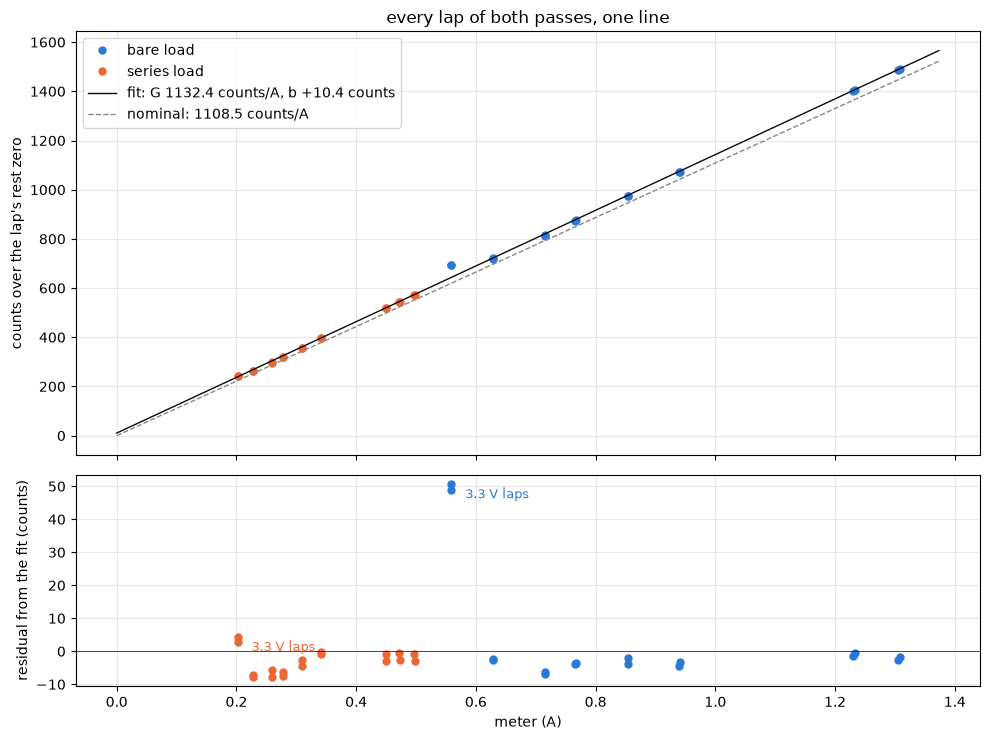

In [8]:
def report(name, g):
    f = laps.line(g["amps"], g["counts"])
    print(f"{name:28s} n={f['n']:2d}  G {f['slope']:7.1f} +/- {f['slope_se']:4.1f} counts/A   b {f['intercept']:+5.1f} +/- {f['intercept_se']:3.1f} counts   rms {f['rms']:5.2f}")
    return f

print("every lap, own zero")
fit_all = report("both loads", T)
fits_all = {p: report(p, T[T["pass_"] == p]) for p in PASSES}
print(f"nominal {BOARD.counts_per_a:.1f} counts/A; both loads {(fit_all['slope'] / BOARD.counts_per_a - 1) * 100:+.2f} % over it")
T["resid_all"] = T["counts"] - (fit_all["slope"] * T["amps"] + fit_all["intercept"])

def fit_figure(S, fit, title):
    # counts against the meter with the line, and the residuals under it, one colour per load
    fig, ax = plt.subplots(2, 1, figsize=(10, 7.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
    x = np.linspace(0, S["amps"].max() * 1.05, 10)
    for p in PASSES:
        g = S[S["pass_"] == p]
        ax[0].plot(g["amps"], g["counts"], "o", ms=5, color=COLOR[p], label=f"{p} load")
        ax[1].plot(g["amps"], g["counts"] - (fit["slope"] * g["amps"] + fit["intercept"]), "o", ms=5, color=COLOR[p])
    ax[0].plot(x, fit["slope"] * x + fit["intercept"], "-", color=INK, lw=1, label=f"fit: G {fit['slope']:.1f} counts/A, b {fit['intercept']:+.1f} counts")
    ax[0].plot(x, BOARD.counts_per_a * x, "--", color=MUTED, lw=1, label=f"nominal: {BOARD.counts_per_a:.1f} counts/A")
    ax[0].set_ylabel("counts over the lap's rest zero"); ax[0].legend(); ax[0].grid(alpha=0.3); ax[0].set_title(title)
    ax[1].axhline(0, color=INK, lw=0.5); ax[1].set_ylabel("residual from the fit (counts)"); ax[1].set_xlabel("meter (A)"); ax[1].grid(alpha=0.3)
    return fig, ax

fig, ax = fit_figure(T, fit_all, "every lap of both passes, one line")
for p in PASSES:                                         # name the 3.3 V points, which sit off the line
    g = T[(T["pass_"] == p) & (T["volts_set"] == 3.3)]
    ax[1].annotate("3.3 V laps", (g["amps"].iloc[0], g["resid_all"].iloc[0]), xytext=(10, -10), textcoords="offset points", color=COLOR[p], fontsize=9)
plt.tight_layout(); plt.show()

The points lie on a line to the eye, and the line sits above the nominal by about 2 %. The residual panel shows the line is pulled. One free line over all 34 points leaves 12.7 counts rms, well over the noise, and nearly all of it is the two 3.3 V laps of the bare pass, 50 counts above the line, with the two 3.3 V laps of the series pass 3 to 4 counts above it. Every other point is within 8 counts. Fitted alone, the bare pass gives an intercept of 40 counts and a slope 3 % under the series pass, which is what the first look gave. That intercept is the 3.3 V laps pulling the low end of the bare line up, not the chain's offset.

### The 3.3 V level and the zero

The lap's own rest zero against the level, both passes, beside VDD at each level. VDD is the ADC's reference, every count is a share of it, and it is read from the chip's 1.2 V reference in the rest rows of the terminal-chain `vdd` pass, which streamed the reference at every level with no meter. That pass is graded in the terminal-chain notebook. Here its rest rows are read for VDD alone, and the rest-noise result gives the same VDD from 3.7 V up.

,volts_set,vref_raw,vdd_v,zero_vdd_pass
0,3.300,1575.414,3.120,1187.000
1,3.700,1495.421,3.287,1203.000
2,4.200,1494.015,3.290,1204.000
3,4.500,1493.284,3.292,1205.000
4,5.000,1492.367,3.294,1206.000
5,5.500,1491.548,3.295,1206.000
6,7.200,1490.621,3.297,1206.000
7,7.600,1490.535,3.298,1206.000


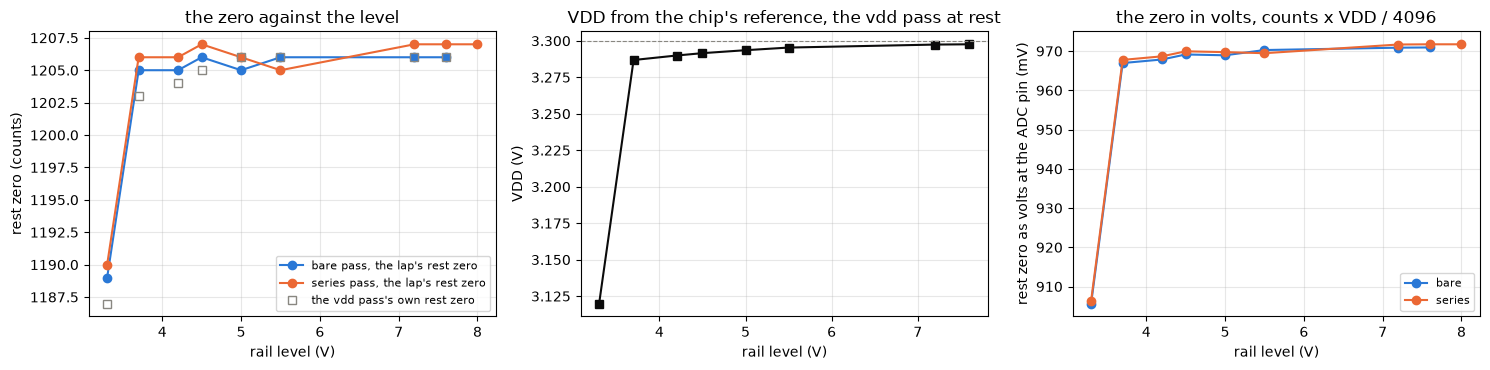

zero at 3.3 V: 1189.5 counts = 906 mV; 3.7 V up: 1205 to 1207 counts = 970 mV
VDD at 3.3 V 3.120 V, -178 mV (-5.4 %) against 3.298 V at 7.6 V; the zero moved -64 mV (-6.6 %), 0.36 V per V of VDD
a fixed-volt zero would read 1275 counts at 3.3 V, a ratiometric one 1206; it read 1190


In [9]:
VDD_PASS = (Path("../../../telemetry") / BOARD.key / "terminal-chain" / "capture-1" / "vdd").resolve()
vdd_levels = pd.read_csv(VDD_PASS / "levels.csv")
rows = []
for _, L in vdd_levels.iterrows():
    d, m = tel.load(VDD_PASS / L["folder"], BOARD)
    b = tel.baseline(d)                                              # the second half of the rest, the reference in every row
    rows.append({"volts_set": L["volts_set"], "vref_raw": b["vref_raw"].mean(), "vdd_v": float(BOARD.vdd_v(b["vref_raw"].mean())),
                 "zero_vdd_pass": b["current_raw"].median()})         # that sitting's own rest zero, for comparison
vdd = pd.DataFrame(rows)
vdd_of = dict(zip(vdd["volts_set"], vdd["vdd_v"])); vdd_of[8.0] = vdd_of[7.6]   # the vdd pass stopped at 7.6 V; the regulator is flat there
T["vdd_v"] = T["volts_set"].map(vdd_of)
T["zero_v"] = T["zero"] * T["vdd_v"] / BOARD.adc_counts            # the zero as volts at the ADC pin
show(vdd, n=None)
Z = T.drop_duplicates(["pass_", "k"])
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for p in PASSES:
    g = Z[Z["pass_"] == p]
    ax[0].plot(g["volts_set"], g["zero"], "o-", color=COLOR[p], label=f"{p} pass, the lap's rest zero")
    ax[2].plot(g["volts_set"], g["zero_v"] * 1e3, "o-", color=COLOR[p], label=p)
ax[0].plot(vdd["volts_set"], vdd["zero_vdd_pass"], "s", mfc="none", color=MUTED, label="the vdd pass's own rest zero")
ax[1].plot(vdd["volts_set"], vdd["vdd_v"], "s-", color=INK)
ax[1].axhline(BOARD.vdd_mv / 1e3, color=MUTED, lw=0.8, ls="--")
ax[0].set_ylabel("rest zero (counts)"); ax[0].set_title("the zero against the level"); ax[0].legend(fontsize=8)
ax[1].set_ylabel("VDD (V)"); ax[1].set_title("VDD from the chip's reference, the vdd pass at rest")
ax[2].set_ylabel("rest zero as volts at the ADC pin (mV)"); ax[2].set_title("the zero in volts, counts x VDD / 4096"); ax[2].legend(fontsize=8)
for a in ax:
    a.set_xlabel("rail level (V)"); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
lo, hi = Z[Z["volts_set"] == 3.3], Z[Z["volts_set"] > 3.4]
dz_v, dvdd = lo["zero_v"].mean() - hi["zero_v"].mean(), vdd_of[3.3] - vdd_of[7.6]
print(f"zero at 3.3 V: {lo['zero'].mean():.1f} counts = {lo['zero_v'].mean() * 1e3:.0f} mV; 3.7 V up: {hi['zero'].min():.0f} to {hi['zero'].max():.0f} counts = {hi['zero_v'].mean() * 1e3:.0f} mV")
print(f"VDD at 3.3 V {vdd_of[3.3]:.3f} V, {dvdd * 1e3:+.0f} mV ({dvdd / vdd_of[7.6] * 100:+.1f} %) against {vdd_of[7.6]:.3f} V at 7.6 V; "
      f"the zero moved {dz_v * 1e3:+.0f} mV ({dz_v / hi['zero_v'].mean() * 100:+.1f} %), {dz_v / dvdd:.2f} V per V of VDD")
print(f"a fixed-volt zero would read {hi['zero'].mean() * vdd_of[7.6] / vdd_of[3.3]:.0f} counts at 3.3 V, a ratiometric one {hi['zero'].mean():.0f}; it read {lo['zero'].mean():.0f}")

Left, the rest zero is 1205 to 1207 counts at every level from 3.7 V up in both passes, 1203 to 1206 in the vdd pass's own rests, and drops to 1189 or 1190 at the 3.3 V level, 1187 in the vdd pass. Middle, VDD is 3.29 V from 3.7 V up and 3.12 V at 3.3 V, 5.4 % lower, which is the regulator out of headroom on a 1S rail. Right, the zero in volts at the pin falls from 970 mV to 906 mV, 64 mV for 178 mV of VDD, which is 0.36 V per V.

A zero that is a fixed voltage would read more counts when VDD falls, about 1275. A zero that is a fixed share of VDD, as a divider from 3V3 gives, would read the same 1206, and that is what the pull-up network on its own predicts. It read 1189, which is 1.4 % under the ratiometric value, so the zero's voltage fell faster than VDD. The pull-ups tie the common mode to the rail and account for the bulk of the move, with moderate confidence. The further 1.4 % at that level is beyond the network, and the op-amp's own behaviour with 180 mV less supply is the candidate this capture does not test.

The counts over the zero at the 3.3 V level can be tested the same way. If the whole excess were the reference, scaling the counts by VDD over 3.3 V would put them back on the line through the higher levels. The pooled zero is also tried in place of the lap's own, to see whether the choice of zero moves the slopes.

In [10]:
T["counts_vdd"] = T["counts"] * T["vdd_v"] / (BOARD.vdd_mv / 1e3)     # the counts as they would read at the nominal reference
hi = T[T["volts_set"] > 3.4]
fit_hi = laps.line(hi["amps"], hi["counts"])                          # the line through the 3.7 V and up laps, own zero
for p in PASSES:
    g = T[(T["pass_"] == p) & (T["volts_set"] == 3.3)]
    pred = fit_hi["slope"] * g["amps"] + fit_hi["intercept"]
    print(f"{p:6s} 3.3 V laps at {g['amps'].mean():.3f} A: counts over zero {g['counts'].mean():.0f}, the 3.7 V up line predicts {pred.mean():.0f}, "
          f"{(g['counts'].mean() / pred.mean() - 1) * 100:+.1f} %; scaled by VDD/3.3 {g['counts_vdd'].mean():.0f}, {(g['counts_vdd'].mean() / pred.mean() - 1) * 100:+.1f} %")
ZERO_POOLED = float(hi["zero"].median())
print(f"\n3.7 V up with one pooled zero of {ZERO_POOLED:.0f} counts in place of each lap's own")
P = hi.assign(counts=hi["current_raw"] - ZERO_POOLED)
report("both loads", P); [report(p, P[P["pass_"] == p]) for p in PASSES];

bare   3.3 V laps at 0.559 A: counts over zero 693, the 3.7 V up line predicts 640, +8.4 %; scaled by VDD/3.3 655, +2.4 %
series 3.3 V laps at 0.203 A: counts over zero 243, the 3.7 V up line predicts 235, +3.5 %; scaled by VDD/3.3 230, -2.2 %

3.7 V up with one pooled zero of 1206 counts in place of each lap's own
both loads                   n=30  G  1134.5 +/-  1.3 counts/A   b  +5.6 +/- 0.9 counts   rms  2.37
bare                         n=14  G  1137.9 +/-  1.8 counts/A   b  +1.7 +/- 1.7 counts   rms  1.49
series                       n=16  G  1157.5 +/-  3.8 counts/A   b  -1.9 +/- 1.4 counts   rms  1.38


The reference accounts for most of the 3.3 V excess and not all. The bare 3.3 V laps read 8 % over the line through the higher levels and 2.4 % over it once scaled by VDD. The series 3.3 V laps read 3.5 % over the line and 2.2 % under it once scaled. The remainders have opposite signs on the two loads, so a single VDD factor read at rest does not describe the 3.3 V laps. VDD under the lap is not in this capture, the lap rows do not carry `vref_raw`, and the two loads draw 0.56 A and 0.20 A from a rail with 170 mV of regulator margin gone. The 3.3 V level is therefore reported as its own observation and left out of the scale fit, which runs from 3.7 V up.

The choice of zero is not what separates the loads. With one pooled zero the common slope moves by half a count per amp and the bare slope by one and a half, both inside their errors, and the series slope by four, since its counts are small and its rest zero wanders between 1205 and 1207 across its levels.

### One line from 3.7 V up

The same figure with the 3.3 V laps left out, and each load's own line dotted over its own range. The thing to see is how tight the residuals get and what shape the series points make around the common line.

3.7 V up, own zero
both loads                   n=30  G  1135.0 +/-  1.2 counts/A   b  +5.3 +/- 0.9 counts   rms  2.19
bare                         n=14  G  1136.5 +/-  1.8 counts/A   b  +3.4 +/- 1.7 counts   rms  1.46
series                       n=16  G  1153.7 +/-  4.9 counts/A   b  -0.9 +/- 1.8 counts   rms  1.80
direction +1                 n=15  G  1134.7 +/-  1.8 counts/A   b  +6.1 +/- 1.3 counts   rms  2.19
direction -1                 n=15  G  1135.3 +/-  1.7 counts/A   b  +4.5 +/- 1.2 counts   rms  2.01
nominal 1108.5 counts/A; both loads +2.40 % over it; the loads' own slopes differ by +17.2 counts/A, +1.5 %


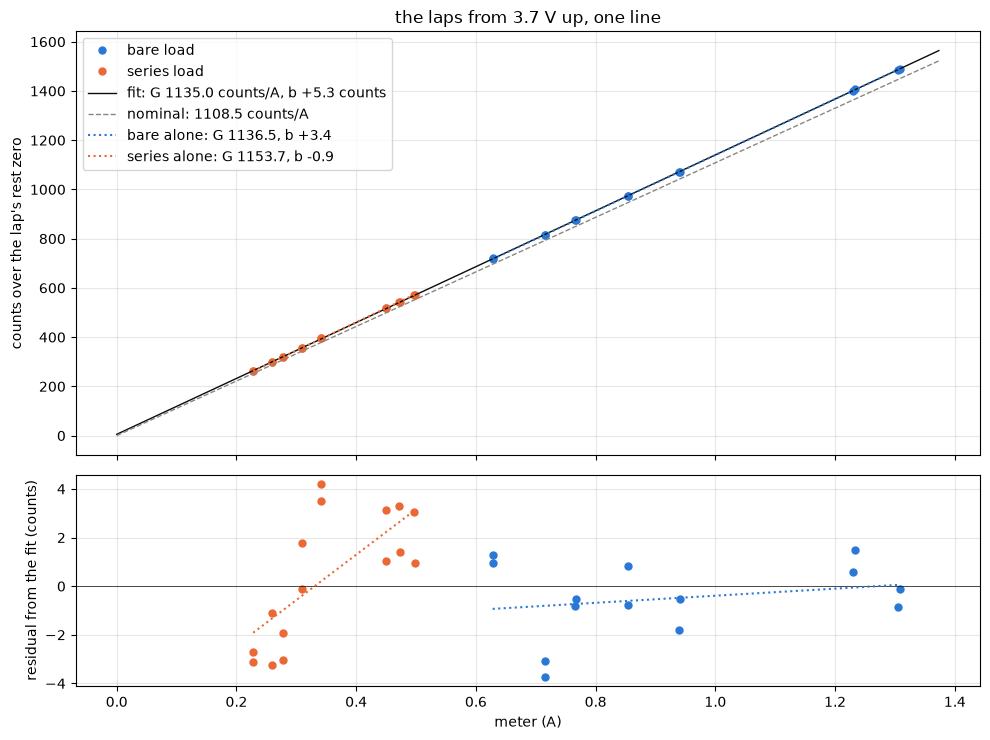

In [11]:
print("3.7 V up, own zero")
fit_hi = report("both loads", hi)
fits_hi = {p: report(p, hi[hi["pass_"] == p]) for p in PASSES}
fits_dir = {d: report(f"direction {d:+d}", hi[hi["dir"] == d]) for d in (1, -1)}
scale_err = (fit_hi["slope"] / BOARD.counts_per_a - 1) * 100
print(f"nominal {BOARD.counts_per_a:.1f} counts/A; both loads {scale_err:+.2f} % over it; the loads' own slopes differ by "
      f"{fits_hi['series']['slope'] - fits_hi['bare']['slope']:+.1f} counts/A, {(fits_hi['series']['slope'] / fits_hi['bare']['slope'] - 1) * 100:+.1f} %")
T["resid"] = T["counts"] - (fit_hi["slope"] * T["amps"] + fit_hi["intercept"])    # residual from the 3.7 V up line, every lap
hi = T[T["volts_set"] > 3.4]
fig, ax = fit_figure(hi, fit_hi, "the laps from 3.7 V up, one line")
for p in PASSES:                                                                  # each load's own line, dotted, over its own range
    g = hi[hi["pass_"] == p]; x = np.linspace(g["amps"].min(), g["amps"].max(), 5)
    ax[0].plot(x, fits_hi[p]["slope"] * x + fits_hi[p]["intercept"], ":", color=COLOR[p], lw=1.5, label=f"{p} alone: G {fits_hi[p]['slope']:.1f}, b {fits_hi[p]['intercept']:+.1f}")
    ax[1].plot(x, fits_hi[p]["slope"] * x + fits_hi[p]["intercept"] - (fit_hi["slope"] * x + fit_hi["intercept"]), ":", color=COLOR[p], lw=1.5)
ax[0].legend(); plt.tight_layout(); plt.show()

With the 3.3 V laps out, one free line through both loads gives $G$ = 1135.0 +/- 1.2 counts per amp and $b$ = +5.3 +/- 0.9 counts with a residual of 2.2 counts rms, which is 2 mA. That is at the noise, the rest floor is about a count and the meter's 1 mA steps are another, so the chain is linear with an offset over 0.23 to 1.31 A and the single-line reading holds. The scale is 2.4 % over the nominal. The two directions give the same slope to 0.05 %. The loads' own lines give 1136.5 +/- 1.8 for bare and 1153.7 +/- 4.9 for series, 1.5 % apart, and their intercepts are +3.4 +/- 1.7 and -0.9 +/- 1.8 counts. Those two intercepts agree within their errors, so the two passes do not read a different in-drive offset at low current than at high.

That bears on where $b$ comes from. An offset that is the op-amp's input offset moving with its common mode, which rises with the shunt voltage, would bend the line back toward the torque-off zero as the current falls, and the pass at the lower currents would read the smaller intercept. An offset that is a ground or reference shift that comes with the bridge being active holds all the way down. The series pass at 0.23 to 0.50 A reads about zero and the bare pass at 0.63 to 1.31 A reads +3.4, a difference of 4 +/- 2.5 counts, which leans toward the common mode and is one and a half standard errors from no difference. It is possible and not settled. A pass at still lower current would settle it, and is in the open questions. The offset of 5 counts is about half the ten counts the one-time characterization gives for this chain, which is noted as an observation.

The residual panel shows what the 1.5 % between the loads' own slopes is. The series points are not scattered around a steeper line. They sit about 2.5 counts under the common line at 3.7 to 4.5 V and about 2.5 counts over it from 5.0 V up, and the dotted series line is the least squares line through a step. The per-level gain makes the same point the other way round.

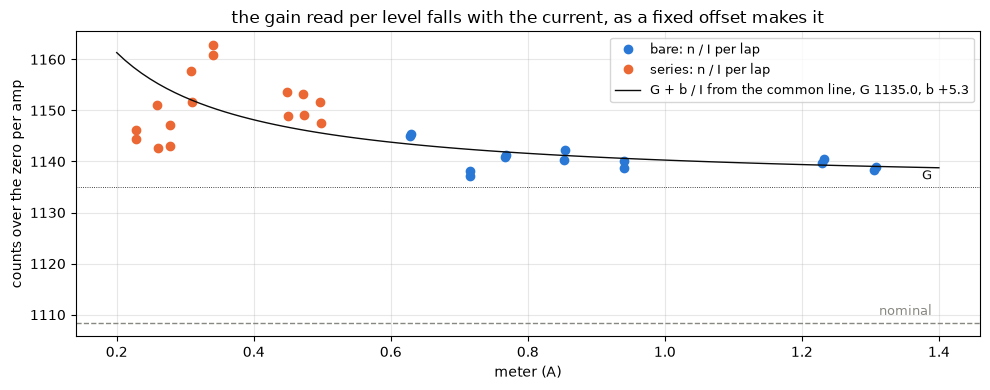

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
x = np.linspace(0.2, 1.4, 100)
for p in PASSES:
    g = hi[hi["pass_"] == p]
    ax.plot(g["amps"], g["gain_per_level"], "o", color=COLOR[p], label=f"{p}: n / I per lap")
ax.plot(x, fit_hi["slope"] + fit_hi["intercept"] / x, "-", color=INK, lw=1, label=f"G + b / I from the common line, G {fit_hi['slope']:.1f}, b {fit_hi['intercept']:+.1f}")
ax.axhline(fit_hi["slope"], color=INK, lw=0.6, ls=":"); ax.axhline(BOARD.counts_per_a, color=MUTED, lw=1, ls="--")
ax.text(1.39, BOARD.counts_per_a + 1.5, "nominal", color=MUTED, fontsize=9, ha="right"); ax.text(1.39, fit_hi["slope"] + 1.5, "G", color=INK, fontsize=9, ha="right")
ax.set_xlabel("meter (A)"); ax.set_ylabel("counts over the zero per amp"); ax.set_title("the gain read per level falls with the current, as a fixed offset makes it")
ax.legend(fontsize=9); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

The gain read per level, counts over the zero divided by the amps, falls from about 1150 at 0.25 A to about 1140 at 1.3 A, and the curve $G + b / I$ from the common line runs through the bare points and between the two groups of series points. A chain with no offset would put every point on the flat line at $G$. The series points above 0.3 A sit over the curve and those below it under, which is the same step.

### Residuals against current, rail, direction and board temperature

The residuals from the common line against three things at once, with the direction as the marker. The thing to see is which panel sorts the series points into two groups.

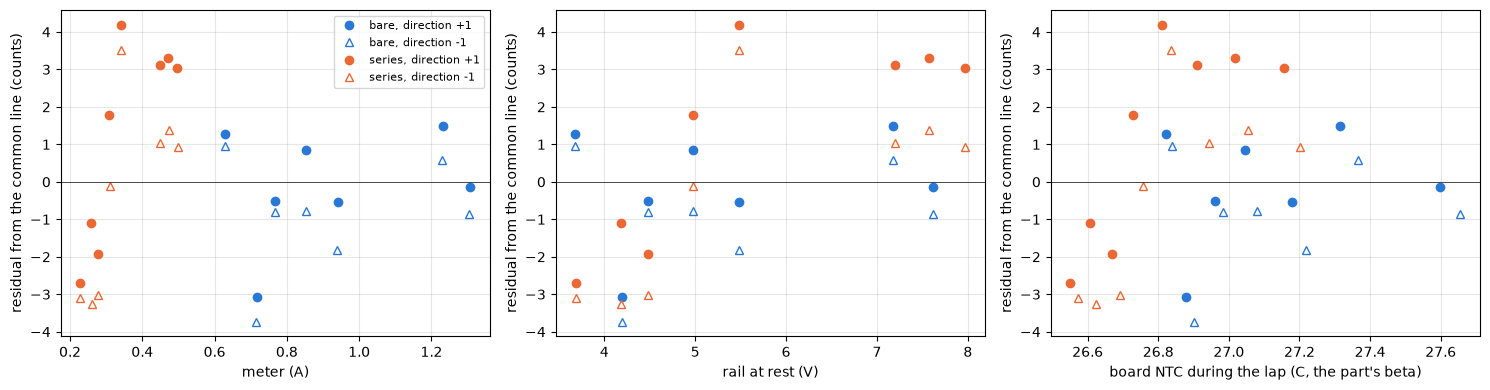

bare   residual at 3.7 to 4.5 V -0.99 counts (sd 2.05, n 6), at 5.0 V up -0.15 (sd 1.07, n 8), step +0.84
series residual at 3.7 to 4.5 V -2.51 counts (sd 0.85, n 6), at 5.0 V up +2.22 (sd 1.40, n 10), step +4.73
direction: b +6.1 +/- 1.3 counts forward, +4.5 +/- 1.2 reverse, G 1134.7 and 1135.3


In [13]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
MARK = {1: "o", -1: "^"}                                           # the direction as the marker shape
for p in PASSES:
    for d in (1, -1):
        g = hi[(hi["pass_"] == p) & (hi["dir"] == d)]
        kw = dict(ls="none", marker=MARK[d], ms=6, color=COLOR[p], mfc=COLOR[p] if d == 1 else "none", label=f"{p}, direction {d:+d}")
        ax[0].plot(g["amps"], g["resid"], **kw)
        ax[1].plot(g["vsys_read"], g["resid"], **kw)
        ax[2].plot(BOARD.ntc_c_beta(g["ntc_raw"]), g["resid"], **kw)
ax[0].set_xlabel("meter (A)"); ax[1].set_xlabel("rail at rest (V)"); ax[2].set_xlabel("board NTC during the lap (C, the part's beta)")
for a in ax:
    a.axhline(0, color=INK, lw=0.5); a.set_ylabel("residual from the common line (counts)"); a.grid(alpha=0.3)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()
for p in PASSES:
    g = hi[hi["pass_"] == p]
    lo_, hi_ = g[g["volts_set"] <= 4.5]["resid"], g[g["volts_set"] >= 5.0]["resid"]
    print(f"{p:6s} residual at 3.7 to 4.5 V {lo_.mean():+.2f} counts (sd {lo_.std():.2f}, n {len(lo_)}), at 5.0 V up {hi_.mean():+.2f} (sd {hi_.std():.2f}, n {len(hi_)}), step {hi_.mean() - lo_.mean():+.2f}")
print(f"direction: b {fits_dir[1]['intercept']:+.1f} +/- {fits_dir[1]['intercept_se']:.1f} counts forward, {fits_dir[-1]['intercept']:+.1f} +/- {fits_dir[-1]['intercept_se']:.1f} reverse, "
      f"G {fits_dir[1]['slope']:.1f} and {fits_dir[-1]['slope']:.1f}")

Inside one pass the current, the rail and the board temperature all move together, since the current is the rail over a fixed load and the board warms as the pass runs, so no panel separates them on its own. The bare points sit within 4 counts of zero everywhere, with no trend against any of the three. The series points form two groups in every panel, 3.7 to 4.5 V about 2.5 counts low and 5.0 V up about 2.2 counts high, a step of 4.7 counts, with both directions in each group. The bare points at the same rails step by 0.8 counts, inside their scatter, so a rail effect would have to act on one load and not the other. The forward points sit a little above the reverse ones in both passes, which the direction fits put at 1.6 counts of offset with the same slope.

### Inside a lap

Each lap's drift of the chip's reading, the last tenth of the settled lap less the first tenth, against the meter's drift over the same lap in counts at the fitted scale. The thing to see is whether the chip drifts with the current or on its own.

,pass_,volts_set,dir,amps,drift_chip,drift_meter_counts,p_shunt_mw,chain
0,bare,3.300,1,0.559,0.277,-1.135,18.749,1.412
1,bare,3.300,-1,0.559,0.460,1.135,18.749,-0.675
2,bare,3.700,1,0.629,0.886,1.135,23.738,-0.249
3,bare,3.700,-1,0.628,1.059,1.135,23.663,-0.076
4,bare,4.200,1,0.716,1.066,0.000,30.759,1.066
5,bare,4.200,-1,0.715,1.028,1.135,30.673,-0.107
6,bare,4.500,1,0.768,0.758,1.135,35.389,-0.377
7,bare,4.500,-1,0.766,0.433,-1.135,35.205,1.568
8,bare,5.000,1,0.854,0.073,0.000,43.759,0.073
9,bare,5.000,-1,0.853,0.946,-1.135,43.708,2.081


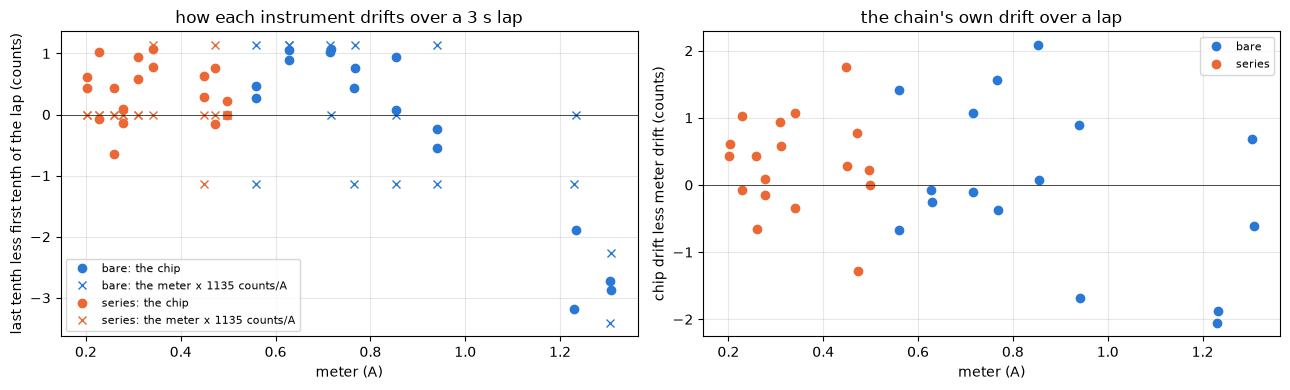

the shunt dissipates 2 to 103 mW over the laps; chain drift over a lap: mean +0.17 counts, sd 0.99


In [14]:
rows = []
for p in PASSES:
    for _, L in levels[levels["pass_"] == p].iterrows():
        d, m = tel.load(CAPTURE / p / L["folder"])
        for seg, g in d[d["seg"] > 0].groupby("seg"):
            s = tel.settled(g); q = len(s) // 10                                      # the settled lap, its first and last tenth
            drift_chip = s["current_raw"].iloc[-q:].mean() - s["current_raw"].iloc[:q].mean()
            mm = dmm[p]; w = mm[(mm["t_host"] >= L["t_start"]) & (mm["t_host"] <= L["t_end"])]
            grp = laps.driven_groups(w["value"])                                       # the meter's two driven stretches in this sweep
            g_m = grp[seg - 1] if seg - 1 < len(grp) else np.array([])
            inner = np.abs(g_m[1:-1])                                                    # drop the first and last packet, either can sit on the ramp
            drift_meter = (inner[-1] - inner[0]) if len(inner) >= 3 else np.nan           # the meter's last inner packet less its first
            rows.append({"pass_": p, "volts_set": L["volts_set"], "dir": int(g["dir"].iloc[0]), "amps": abs(np.median(g_m)) if len(g_m) else np.nan,
                         "drift_chip": drift_chip, "drift_meter_counts": drift_meter * fit_hi["slope"], "p_shunt_mw": np.median(g_m) ** 2 * BOARD.shunt_mohm if len(g_m) else np.nan})
drift = pd.DataFrame(rows)
drift["chain"] = drift["drift_chip"] - drift["drift_meter_counts"]                     # what the chain drifts on its own
show(drift, n=None)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for p in PASSES:
    g = drift[drift["pass_"] == p]
    ax[0].plot(g["amps"], g["drift_chip"], "o", color=COLOR[p], label=f"{p}: the chip")
    ax[0].plot(g["amps"], g["drift_meter_counts"], "x", color=COLOR[p], label=f"{p}: the meter x {fit_hi['slope']:.0f} counts/A")
    ax[1].plot(g["amps"], g["chain"], "o", color=COLOR[p], label=p)
ax[0].set_ylabel("last tenth less first tenth of the lap (counts)"); ax[0].set_title("how each instrument drifts over a 3 s lap")
ax[1].set_ylabel("chip drift less meter drift (counts)"); ax[1].set_title("the chain's own drift over a lap")
for a in ax:
    a.axhline(0, color=INK, lw=0.5); a.set_xlabel("meter (A)"); a.grid(alpha=0.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"the shunt dissipates {drift['p_shunt_mw'].min():.0f} to {drift['p_shunt_mw'].max():.0f} mW over the laps; "
      f"chain drift over a lap: mean {drift['chain'].mean():+.2f} counts, sd {drift['chain'].std():.2f}")

At 1.2 and 1.3 A the chip's reading falls 2 to 3 counts over the lap and the meter falls by the same 2 to 3 mA, so the current itself is falling, which is the bare load warming at 8 W, and the chain follows it. Below 1 A both drift by a count or less. The chip less the meter is within about a count on every lap, with the meter's 1 mA steps as the limit of the comparison. The shunt dissipates 2 to 103 mW over these laps, and if its value moved with that the chain would drift over the lap at the top levels on its own. It does not, to about a count. The amplifier's settle is inside this as well. The first 2 ms after the drive opens are skipped, and the first tenth of the lap reads the same as the last to a count.

### Direction symmetry

Forward less reverse at each level. The chip's difference in counts beside the meter's own difference at the fitted scale. The thing to see is whether the chip reads the two directions apart by more than the current differs.

,pass_,volts_set,amps_rev,amps_fwd,counts_rev,counts_fwd,d_chip,d_meter_counts,d_chain
0,bare,3.300,0.559,0.559,692.344,694.030,1.686,0.000,1.686
1,bare,3.700,0.628,0.629,718.993,720.462,1.468,1.135,0.333
2,bare,4.200,0.715,0.716,813.064,814.847,1.783,1.135,0.648
3,bare,4.500,0.766,0.768,873.864,876.436,2.572,2.270,0.302
4,bare,5.000,0.853,0.854,973.216,975.407,2.191,0.568,1.624
5,bare,5.500,0.940,0.941,1070.359,1072.777,2.418,1.135,1.283
6,bare,7.200,1.230,1.233,1401.914,1406.213,4.299,3.405,0.894
7,bare,7.600,1.305,1.308,1485.600,1489.733,4.133,3.405,0.728
8,series,3.300,0.203,0.202,243.004,243.491,0.487,-1.135,1.622
9,series,3.700,0.228,0.228,260.941,261.343,0.402,0.000,0.402


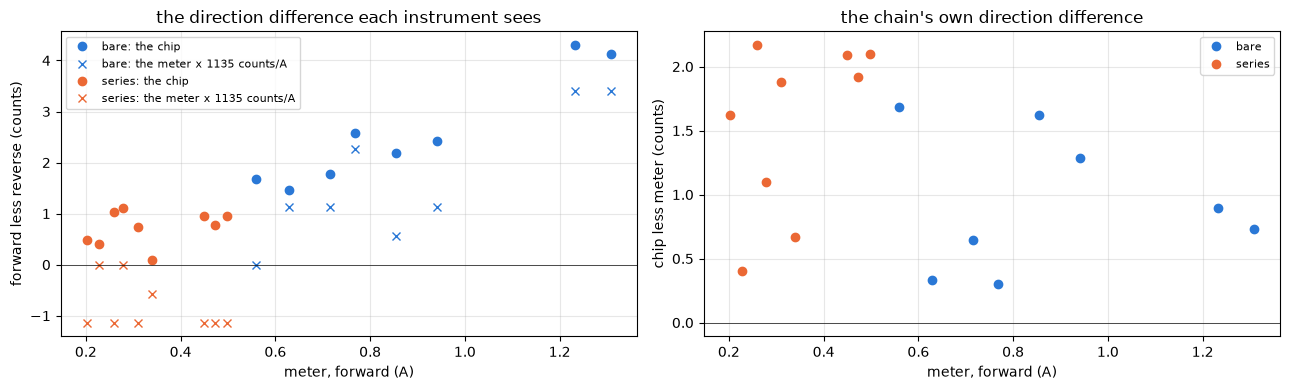

chain direction difference, 3.7 V up: mean +1.21 counts, sd 0.70, bare +0.83, series +1.54


In [15]:
piv = T.pivot_table(index=["pass_", "volts_set"], columns="dir", values=["counts", "amps"]).reset_index()
piv.columns = ["pass_", "volts_set", "amps_rev", "amps_fwd", "counts_rev", "counts_fwd"]
piv["d_chip"] = piv["counts_fwd"] - piv["counts_rev"]                             # the chip, forward less reverse
piv["d_meter_counts"] = (piv["amps_fwd"] - piv["amps_rev"]) * fit_hi["slope"]     # the meter's own difference, in counts
piv["d_chain"] = piv["d_chip"] - piv["d_meter_counts"]                            # what the chain adds to the direction
show(piv, n=None)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for p in PASSES:
    g = piv[piv["pass_"] == p]
    ax[0].plot(g["amps_fwd"], g["d_chip"], "o", color=COLOR[p], label=f"{p}: the chip")
    ax[0].plot(g["amps_fwd"], g["d_meter_counts"], "x", color=COLOR[p], label=f"{p}: the meter x {fit_hi['slope']:.0f} counts/A")
    ax[1].plot(g["amps_fwd"], g["d_chain"], "o", color=COLOR[p], label=p)
ax[0].set_ylabel("forward less reverse (counts)"); ax[0].set_title("the direction difference each instrument sees")
ax[1].set_ylabel("chip less meter (counts)"); ax[1].set_title("the chain's own direction difference")
for a in ax:
    a.axhline(0, color=INK, lw=0.5); a.set_xlabel("meter, forward (A)"); a.grid(alpha=0.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()
g37 = piv[piv["volts_set"] > 3.4]
print(f"chain direction difference, 3.7 V up: mean {g37['d_chain'].mean():+.2f} counts, sd {g37['d_chain'].std():.2f}, "
      f"bare {g37[g37.pass_ == 'bare']['d_chain'].mean():+.2f}, series {g37[g37.pass_ == 'series']['d_chain'].mean():+.2f}")

The current itself differs by direction. On the bare load the meter reads forward 1 to 3 mA higher than reverse, growing with the current, which is the bridge's two legs not matching to about 10 mOhm, and the chip follows that to within a count or two. Taking the meter's difference out, the chain reads forward above reverse by 1.2 counts on average, about 1 mA, 0.8 on the bare load and 1.5 on the series load, with no clear trend with the current. A difference that does not grow with the current is an offset and not a copper drop in the shunt's sense path. The meter's own zero on the 20 A range, read one way and the other, is inside this comparison and is of the same size, so the 1.2 counts is an upper bound on the chain rather than a measured asymmetry.

### The taps under load

The terminal taps give a second current with no part of the current chain in it, the tap difference over the load's stage 0 value. The chip at the fitted scale and the meter, each as a ratio to that tap current, per lap. The thing to see is whether the chip and the meter move together against the taps or apart.

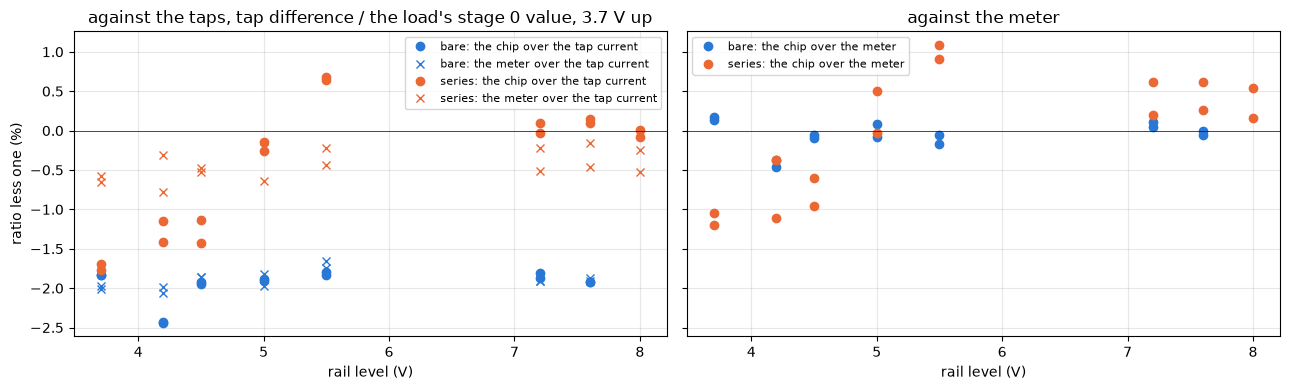

bare   3.7 V up: meter over the tap current -1.90 % with the load alone, +0.89 % with the leads and ammeter in the loop
series 3.7 V up: meter over the tap current -0.44 % with the load alone, +0.51 % with the leads and ammeter in the loop
bare   3.3 V laps: the chip over the tap current -5.1 %, the meter over the tap current -12.5 %
series 3.3 V laps: the chip over the tap current -5.4 %, the meter over the tap current -8.7 %


In [16]:
T["amps_tap"] = T["tap_v"] / T["pass_"].map(R_LOAD)                                # the load alone, no leads
T["amps_tap_leads"] = T["tap_v"] / (T["pass_"].map(R_LOAD) + R_LEADS)              # the load plus the leads and ammeter value from stage 0
T["amps_chip"] = (T["counts"] - fit_hi["intercept"]) / fit_hi["slope"]             # the chip at the fitted scale and offset
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for p in PASSES:
    g = T[(T["pass_"] == p) & (T["volts_set"] > 3.4)]                                 # 3.7 V up; the 3.3 V laps are printed below
    ax[0].plot(g["volts_set"], (g["amps_chip"] / g["amps_tap"] - 1) * 100, "o", color=COLOR[p], label=f"{p}: the chip over the tap current")
    ax[0].plot(g["volts_set"], (g["amps"] / g["amps_tap"] - 1) * 100, "x", color=COLOR[p], label=f"{p}: the meter over the tap current")
    ax[1].plot(g["volts_set"], (g["amps_chip"] / g["amps"] - 1) * 100, "o", color=COLOR[p], label=f"{p}: the chip over the meter")
ax[0].set_ylabel("ratio less one (%)"); ax[0].set_title("against the taps, tap difference / the load's stage 0 value, 3.7 V up")
ax[1].set_title("against the meter")
for a in ax:
    a.axhline(0, color=INK, lw=0.5); a.set_xlabel("rail level (V)"); a.grid(alpha=0.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()
for p in PASSES:
    g = hi[hi["pass_"] == p]
    print(f"{p:6s} 3.7 V up: meter over the tap current {((g['amps'] / T.loc[g.index, 'amps_tap'] - 1) * 100).mean():+.2f} % with the load alone, "
          f"{((g['amps'] / T.loc[g.index, 'amps_tap_leads'] - 1) * 100).mean():+.2f} % with the leads and ammeter in the loop")
for p in PASSES:
    g = T[(T["pass_"] == p) & (T["volts_set"] == 3.3)]
    print(f"{p:6s} 3.3 V laps: the chip over the tap current {((g['amps_chip'] / g['amps_tap'] - 1) * 100).mean():+.1f} %, the meter over the tap current {((g['amps'] / g['amps_tap'] - 1) * 100).mean():+.1f} %")

Against the taps the meter sits flat through each pass, 1.9 % under the tap current on the bare load and 0.4 % under on the series load with the load's value alone, and 0.9 % and 0.5 % over it with the stage 0 leads and ammeter value added, which brackets the meter's own shunt and probe leads that sit inside the tap loop here. The chip steps up by about 1.3 % between the 4.5 V and 5.0 V laps of the series pass against the taps, the same step it shows against the meter, while the meter against the taps does not move there. That puts the step in the current channel and not in the meter, with moderate confidence. The 3.3 V laps read 5 % under the tap current on both loads, which is the tap channel reading high on the same low reference. The terminal-chain notebook grades the taps properly.

### Two loads, one line

The alternatives for the 1.5 % between the loads' own slopes, and what this capture says about each.

| Candidate | What the data says | Confidence |
|---|---|---|
| Short ranges fitted with their own intercepts, the chain linear with an offset | One free line over both loads leaves 2.2 counts rms, at the noise. | Likely. This is the reading the result file carries. |
| A step in the current channel during the series pass, between the 4.5 V and 5.0 V laps | The series residuals sit in two flat groups 4.7 counts apart, both directions in each, against the meter and against the taps alike, and the meter against the taps does not move. The bare pass at the same rails shows no step. The rest zero does not step. | The step is in this data with high confidence, and a second series pass repeats it to the count. The converter's own linearity, mapped in the terminal-chain notebook, accounts for about one count of it. The rest is open. |
| A current-dependent term below about 0.3 A | The split falls at 0.28 and 0.31 A as well as at 4.5 and 5.0 V, and it is a step, not a curve. The loads' ranges do not overlap. | Unlikely but not excluded. A third load that overlaps both ranges tests it. |
| The board's temperature, the gain or the offset moving as the pass runs | The board moves less than a degree over a pass. The series points step at about 26.8 C on the board NTC, where the bare points over 26.8 to 27.6 C do not. The characterized gain drift is a quarter of a percent over 30 C, far smaller than the step. | Possible. The opamp-temperature experiment is where it is measured. |
| The shunt's self-heating, the amplifier's settle | The chain drifts within a count over every 3 s lap, at 2 to 103 mW in the shunt, and the first tenth of a lap reads as the last. | Unlikely. |
| The meter's fixed error of about 1.5 mA at low current | A fixed error moves $b$ by about 1.7 counts and not $G$. | Does not make the slope difference. Likely 1 to 2 counts of $b$. |


### The amplifier alone, the rs1 pass

The pass with the meter on DC millivolts across a twisted pair soldered to the shunt pads, the bare load straight across the terminals, the same levels. The meter's reading is the shunt's own drop, so counts against it are the amplifier and the ADC with the shunt's value out of the route, on the meter's 0.1 % plus 50 uV range rather than the 20 A jack's 2 % plus 25 mA. The nominal is the gain of 14.884 over the 3.3 V reference, 18.47 counts per millivolt. Three things to read: the slope against the nominal, which is the amplifier's share of the chain's 2.4 %; the intercept, which the driver's own supply current through the shunt would put near zero here and leave at +5 against the ammeter, since that current flows through the shunt and not through a series meter; and the chain's counts per amp over this slope, which is the shunt's value as the 20 A jack sees it.


rs1 pass: 16 laps, 6 to 7 meter packets per lap, shunt 39.7 to 82.0 mV from 3.7 V up
3.7 V up: 18.654 +/- 0.019 counts/mV, intercept +1.55 +/- 1.16 counts, rms 1.00; nominal 18.474, +0.97 % over it; at the measured VDD 3.292 V the nominal is 18.518 and the amplifier is +0.73 % over
chain 1135.0 counts/A over amplifier 18.654 counts/mV = shunt 60.85 mOhm, +1.4 % over 60, through the 20 A jack's class
chain over nominal +2.40 % = amplifier +0.97 % + +1.43 % for the shunt and the 20 A jack together
intercept against the ammeter +5.3 +/- 0.9 counts, against the shunt's millivolts +1.55 +/- 1.16; the difference +3.7 counts is 3.3 mA through the shunt that the ammeter does not carry
3.3 V laps: 20.03 counts/mV, +8.4 % over nominal, zero 1191 against 1205 from 3.7 V up
forward less reverse, counts: [1.9, 1.6, 2.1, 2.6, 3.0, 5.1, 4.8]  the meter's millivolts as counts: [1.5, 1.8, 2.1, 2.6, 2.8, 4.8, 3.9]


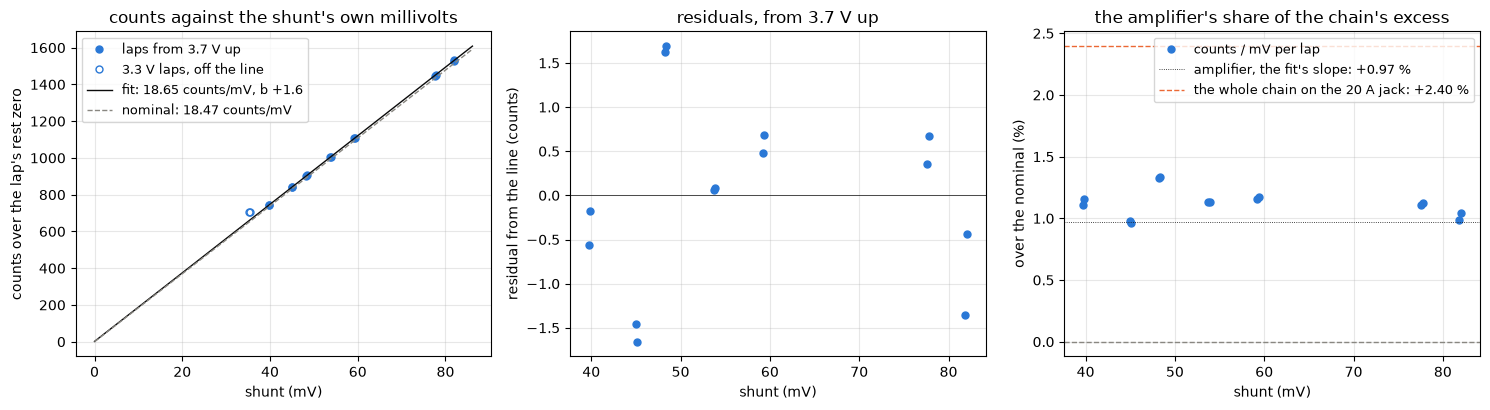

In [17]:
# the rs1 pass: the meter on DC millivolts across the shunt pads, the bare load alone on the terminals
dmm_rs1 = b41t.load(CAPTURE / "rs1" / "dmm.csv")
R = laps.table(CAPTURE / "rs1", BOARD, dmm_rs1[dmm_rs1["function"] == "DC V"])
R["counts"] = (R["current_raw"] - R["zero"]).abs()                    # counts over the lap's own torque-off zero
R["shunt_mv"] = R["meter"].abs() * 1e3                                # the shunt's millivolts as the meter read them
R["counts_per_mv"] = R["counts"] / R["shunt_mv"]
NOM_MV = BOARD.gain_milli / 1e3 * BOARD.adc_counts / BOARD.vdd_mv     # nominal counts per millivolt of shunt: the gain over the reference
r_hi = R[R["volts_set"] > 3.4]
r33 = R[R["volts_set"] == 3.3]
fit_mv = laps.line(r_hi["shunt_mv"], r_hi["counts"])
amp_err = (fit_mv["slope"] / NOM_MV - 1) * 100
nom_mv_vdd = NOM_MV * BOARD.vdd_mv / 1e3 / RN["vdd_v"]["value"]      # the same nominal at the measured VDD
shunt_mohm = fit_hi["slope"] / fit_mv["slope"]                        # the chain's counts per amp over the amplifier's counts per millivolt
print(f"rs1 pass: {len(R)} laps, {r_hi['meter_n'].min()} to {r_hi['meter_n'].max()} meter packets per lap, shunt {r_hi['shunt_mv'].min():.1f} to {r_hi['shunt_mv'].max():.1f} mV from 3.7 V up")
print(f"3.7 V up: {fit_mv['slope']:.3f} +/- {fit_mv['slope_se']:.3f} counts/mV, intercept {fit_mv['intercept']:+.2f} +/- {fit_mv['intercept_se']:.2f} counts, rms {fit_mv['rms']:.2f}; "
      f"nominal {NOM_MV:.3f}, {amp_err:+.2f} % over it; at the measured VDD {RN['vdd_v']['value']:.3f} V the nominal is {nom_mv_vdd:.3f} and the amplifier is {(fit_mv['slope'] / nom_mv_vdd - 1) * 100:+.2f} % over")
print(f"chain {fit_hi['slope']:.1f} counts/A over amplifier {fit_mv['slope']:.3f} counts/mV = shunt {shunt_mohm:.2f} mOhm, {(shunt_mohm / BOARD.shunt_mohm - 1) * 100:+.1f} % over {BOARD.shunt_mohm}, through the 20 A jack's class")
print(f"chain over nominal {scale_err:+.2f} % = amplifier {amp_err:+.2f} % + {scale_err - amp_err:+.2f} % for the shunt and the 20 A jack together")
d_b = fit_hi["intercept"] - fit_mv["intercept"]
print(f"intercept against the ammeter {fit_hi['intercept']:+.1f} +/- {fit_hi['intercept_se']:.1f} counts, against the shunt's millivolts {fit_mv['intercept']:+.2f} +/- {fit_mv['intercept_se']:.2f}; "
      f"the difference {d_b:+.1f} counts is {d_b / fit_mv['slope'] / BOARD.shunt_mohm * 1e3:.1f} mA through the shunt that the ammeter does not carry")
print(f"3.3 V laps: {r33['counts_per_mv'].mean():.2f} counts/mV, {(r33['counts_per_mv'].mean() / NOM_MV - 1) * 100:+.1f} % over nominal, zero {r33['zero'].iloc[0]:.0f} against {r_hi['zero'].median():.0f} from 3.7 V up")
fw = r_hi[r_hi["dir"] > 0].set_index("k"); rv = r_hi[r_hi["dir"] < 0].set_index("k")
print("forward less reverse, counts:", (fw["counts"] - rv["counts"]).round(1).tolist(), " the meter's millivolts as counts:", ((fw["shunt_mv"] - rv["shunt_mv"]) * fit_mv["slope"]).round(1).tolist())

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
x = np.linspace(0, r_hi["shunt_mv"].max() * 1.05, 10)
ax[0].plot(r_hi["shunt_mv"], r_hi["counts"], "o", ms=5, color=BLUE, label="laps from 3.7 V up")
ax[0].plot(r33["shunt_mv"], r33["counts"], "o", ms=5, mfc="none", color=BLUE, label="3.3 V laps, off the line")
ax[0].plot(x, fit_mv["slope"] * x + fit_mv["intercept"], "-", color=INK, lw=1, label=f"fit: {fit_mv['slope']:.2f} counts/mV, b {fit_mv['intercept']:+.1f}")
ax[0].plot(x, NOM_MV * x, "--", color=MUTED, lw=1, label=f"nominal: {NOM_MV:.2f} counts/mV")
ax[0].set_xlabel("shunt (mV)"); ax[0].set_ylabel("counts over the lap's rest zero"); ax[0].set_title("counts against the shunt's own millivolts"); ax[0].legend(fontsize=9); ax[0].grid(alpha=0.3)
ax[1].plot(r_hi["shunt_mv"], r_hi["counts"] - (fit_mv["slope"] * r_hi["shunt_mv"] + fit_mv["intercept"]), "o", ms=5, color=BLUE)
ax[1].axhline(0, color=INK, lw=0.5); ax[1].set_xlabel("shunt (mV)"); ax[1].set_ylabel("residual from the line (counts)"); ax[1].set_title("residuals, from 3.7 V up"); ax[1].grid(alpha=0.3)
ax[2].plot(r_hi["shunt_mv"], (r_hi["counts_per_mv"] / NOM_MV - 1) * 100, "o", ms=5, color=BLUE, label="counts / mV per lap")
ax[2].axhline(amp_err, color=INK, lw=0.6, ls=":", label=f"amplifier, the fit's slope: {amp_err:+.2f} %")
ax[2].axhline(scale_err, color=ORANGE, lw=1, ls="--", label=f"the whole chain on the 20 A jack: {scale_err:+.2f} %")
ax[2].axhline(0, color=MUTED, lw=1, ls="--")
ax[2].set_xlabel("shunt (mV)"); ax[2].set_ylabel("over the nominal (%)"); ax[2].set_title("the amplifier's share of the chain's excess"); ax[2].legend(fontsize=9); ax[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

The amplifier reads 18.65 +/- 0.02 counts per millivolt from 3.7 V up, 1.0 % over the nominal at the nominal reference and 0.7 % over it at the measured VDD of 3.292 V, with a residual of 1.0 count rms, at the rest floor. The per-lap ratios sit within 0.2 % of each other over 40 to 82 mV with no trend. The residuals carry one shape: the 4.2 V laps, at raw code 2046, sit 1.5 counts under the line and the 4.5 V laps, at 2110, 1.7 counts over, a step of about 3 counts across the converter's carry at 2048, the size of the series pass's step at 1536. Two laps on each side is a hint and not a map, and it goes with the series step in the open questions. So the amplifier owns about a percent of the chain's 2.4 %, which two 0.5 % gain resistors can give, and the remaining 1.4 % sits in the shunt and the 20 A jack together. The chain's counts per amp over this slope puts the shunt at 60.85 mOhm, 1.4 % over its 60 mOhm label, which is inside the part's 1 % and the jack's 2 % at once, so the shunt's own value stays with the jack's class until a reference shunt is in the loop.

The intercept against the shunt's millivolts is +1.6 +/- 1.2 counts, against +5.3 +/- 0.9 against the ammeter. The difference, about 4 counts, is 3 mA that flows through the shunt and not through the ammeter. That is the shape the driver's supply current makes: it returns through the shunt, so the chip and the shunt meter both see it and the series ammeter does not. An offset in the op-amp or a ground shift would read the same against either meter. So the in-drive offset is most likely the driver's own current, with moderate to high confidence, about 3 mA on this board against 9 on the sister board, and the count or two left is inside the intercept's error.

The two directions differ by 2 to 5 counts, and the meter's millivolts differ by the same, so the direction difference is in the current the bridge's two legs pass and not in the chain. The 3.3 V laps read 8 % over the nominal with the zero 14 counts lower, which is the reference in dropout as before, and are left out of the line.


### The results file

The scale and the in-drive offset from the common line over the 3.7 V and up laps of both loads, own zero, with their standard errors as the bounds. The bare and series slopes alone, the every-lap fit for comparison, the direction difference, the rest zero, and how far the 3.3 V level sits off the line. From the rs1 pass, the amplifier's counts per millivolt of shunt with its intercept and its excess over the nominal, and the shunt's value as the chain over the amplifier, which carries the 20 A jack's class.


In [18]:
q = results.quantity
def se_q(f, key, unit):
    return q(f[key], f[key] - f[key + "_se"], f[key] + f[key + "_se"], unit)
rest_hi = hi.drop_duplicates(["pass_", "k"])["zero"]
rest_33 = T[T["volts_set"] == 3.3].drop_duplicates(["pass_", "k"])["zero"]
dev33 = {p: (T[(T["pass_"] == p) & (T["volts_set"] == 3.3)]["counts"].mean() /
             (fit_hi["slope"] * T[(T["pass_"] == p) & (T["volts_set"] == 3.3)]["amps"].mean() + fit_hi["intercept"]) - 1) * 100 for p in PASSES}
results.write("1-board", "current-scale", CAPTURE, pair=BOARD.key,
              notes="DC laps at 100 % duty on the bare 5 ohm and series 15 ohm loads, the DMM in series on its 20 A range; counts over the lap's own torque-off zero "
                    "= drive_offset_counts + counts_per_a x amps, one line through both loads over the 3.7 V and up laps, 0.23 to 1.31 A; the 3.3 V level "
                    "sits off the line and is reported apart; the rs1 pass, the meter on DC mV across the shunt pads, grades the amplifier alone as "
                    "amp_counts_per_mv; shunt_mohm is the chain over the amplifier and carries the 20 A jack's class",
              counts_per_a=se_q(fit_hi, "slope", "counts/A"),
              drive_offset_counts=se_q(fit_hi, "intercept", "counts"),
              residual_rms_counts=q(fit_hi["rms"], unit="counts"),
              scale_over_nominal_pct=q(scale_err, unit="%"),
              amps_range=q(hi["amps"].max(), lo=hi["amps"].min(), hi=hi["amps"].max(), unit="A"),
              amp_counts_per_mv=se_q(fit_mv, "slope", "counts/mV"),
              amp_offset_counts=se_q(fit_mv, "intercept", "counts"),
              amp_over_nominal_pct=q(amp_err, unit="%"),
              shunt_mohm=q(shunt_mohm, unit="mOhm"),
              counts_per_a_bare=se_q(fits_hi["bare"], "slope", "counts/A"),
              drive_offset_bare_counts=se_q(fits_hi["bare"], "intercept", "counts"),
              counts_per_a_series=se_q(fits_hi["series"], "slope", "counts/A"),
              drive_offset_series_counts=se_q(fits_hi["series"], "intercept", "counts"),
              counts_per_a_every_lap=se_q(fit_all, "slope", "counts/A"),
              drive_offset_every_lap_counts=se_q(fit_all, "intercept", "counts"),
              direction_counts=q(g37["d_chain"].mean(), lo=g37["d_chain"].min(), hi=g37["d_chain"].max(), unit="counts"),
              rest_zero_counts=q(rest_hi.median(), lo=rest_hi.min(), hi=rest_hi.max(), unit="counts"),
              rest_zero_3v3_counts=q(rest_33.mean(), lo=rest_33.min(), hi=rest_33.max(), unit="counts"),
              vdd_3v3_v=q(vdd_of[3.3], unit="V"),
              deviation_3v3_bare_pct=q(dev33["bare"], unit="%"),
              deviation_3v3_series_pct=q(dev33["series"], unit="%"))

PosixPath('stages/1-board/current-scale/results/dev-v006-2A-D.json')

## Limitations

- The meter bounds everything. Its class on the 20 A range is 2 % of the reading plus 25 mA, from the stage 0 result, so the scale here is known to 2 % at best through this meter, and its fixed error of about 1.5 mA at low current, far inside the 25 mA the class allows, is inside the offset. Its 1 mA steps are 0.4 % of a series lap reading, and the median of six packets does not remove that. The rs1 pass is on the 0.1 % plus 50 uV range, so the amplifier is bounded far tighter than the chain.
- The shunt is graded only through the 20 A jack. The rs1 pass separates the amplifier to 0.1 %, and the shunt's value then comes out as the chain over the amplifier with the jack's 2 % on it. A reference shunt of known value in the loop is what grades the shunt itself.
- The zero is the lap's own torque-off rest, read before the lap. At 100 % duty the bridge does not switch, so there is no brake half in the period and a bias estimate taken from the brake half has nothing to sample. Such an estimate holds the zero it had before the lap through the whole three seconds, and so does this analysis. A zero that drifts during the lap, from the board warming under the load resistor or the amplifier's offset moving, is invisible here. The drift figure bounds the chain's drift within a lap to about a count against the meter, but it does not separate a moving zero from a moving gain.
- The 3.3 V level is not graded. The reference is in dropout there, the zero moves, and VDD under the lap is not in the data.
- The laps are DC. Under switching the crest sample lands on a rising current, and the sample-timing experiment is where that lives.
- The two loads' current ranges meet at 0.50 and 0.56 A and do not overlap, so no current was read on both loads.
- The loads' stage 0 values enter only the tap cross-check, not the scale.

## What earlier characterization established

Before this stage the current chain was characterized in one-time efforts on a sister board of this revision, the same shunt, network and pull-ups, each aimed at understanding one piece of its physics rather than at grading it. Their data is not reused here, but their conclusions bear on what this notebook leaves open.

- The op-amp was characterized over board temperature with meter wires on the shunt pads, so its gain was read without the shunt in the loop. In normal mode the gain sits a quarter percent over the nominal 14.884 at room and drifts a quarter percent from 28 to 60 C with no dependence on level. The high-speed mode drifts 4 % with a level-dependent term, so normal mode is the one to run. The op-amp's offset depends on its input common mode and is flat only once the inputs sit above about 0.6 V, and the bare network put them at 0.07 V.
- The two 1.5 kohm pull-ups from 3V3 on both op-amp inputs exist to lift the inputs to about 0.75 V, into that flat region. They cut the turn-on settling of the current reading by a quarter and took the common-mode term out of the thermal drift. They are 1 % thick-film parts soldered on by hand, the zero spread between the boards of this revision comes from them, and a rev 2B board is to carry them as 0.5 % thin-film footprints.
- The normal-mode zero moves about a quarter count per degree of board, so a three second lap at 100 mW in the shunt cannot move it a count, and the per-lap zero holds within a lap. Between DC sets the zero was seen to rise 6 to 10 counts over a run even with the board's thermistor flat, cause unresolved, either local heat the thermistor misses or the offset settling after high current. That is why each lap here carries its own zero read just before it.
- The offset that appears when the driver wakes was attributed to the driver's own supply current returning through the shunt, about 9 mA and 10 counts on the sister board, present in every off-state sample from 5 % to 50 % duty with no winding current in the shunt. Under that reading it comes with the bridge being active and not with the common mode, and it predicts an intercept that holds at low current rather than bending toward the zero. The discriminating test, laps at small currents, was never run, and this board's 5 counts is half the sister board's 10, so I carry the attribution as likely and not settled. The DC laps there also fitted as well through zero with a slope a quarter percent from nominal as with a ten-count intercept, so the fixed offset the Purpose cites is the intercept of a line the data could also fold into the slope.
- Three earlier readings put the sister board's chain within a percent of nominal, the amplifier through the shunt pads on the meter's millivolt range at +0.2 % and +0.5 % in two sessions and the whole chain with a series ammeter at +0.9 %. The +2.4 % here is outside all three but inside the meter's class on the 20 A jack, 2 % of the reading plus 25 mA from the stage 0 result, where the earlier figures were millivolts across the shunt on a range twenty times tighter. The rs1 pass here reads the amplifier the same way and puts it at +1.0 %, twice the sister board's, which two 0.5 % parts allow. The rest of the 2.4 % sits in the shunt and the jack.
- The rest zero and the op-amp's reference come from 3V3, ratiometric with the converter's reference, and the regulator starts to drop out when the rail falls below about 3.4 V, measured once. No earlier work drove the chain at a 3.3 V rail. The lowest earlier rails were USB at 4.4 V.
- Nothing earlier bears on the series step. The earlier DC levels on the sister board had no 5.0 V level and fit one line to 1.6 counts.

## Open questions

- Whether the in-drive offset is the driver's supply current through the shunt. The rs1 pass reads an intercept of +1.6 +/- 1.2 counts against the shunt's own millivolts and +5.3 against the ammeter, the signature of a current that flows through the shunt and not the ammeter, so that attribution is now likely. The two loads' intercepts against the ammeter still differ by 4 +/- 2.5 counts, one and a half standard errors, and the constants do not wait on it. An offset taken as a constant is off by under 5 counts, about 4 mA, if it does bend toward zero at low current, under any limit or trip worth setting. A pass at a lower current reads it. The three loads in series, bare, cap and series for about 25 ohm, give 0.15 to 0.32 A over the same levels with the parts on hand. An offset that follows the common mode bends toward zero there, and one that comes with the bridge being active holds at about 5 counts.
- What stepped in the series pass between the 4.5 V and 5.0 V laps. A second series pass, `capture.py series 2`, repeated it at 4.4 counts with every lap within a count of the first pass, so it is a fixed feature of those laps and not a one-off. The laps straddle raw code 1536, a carry of the converter, and the terminal-chain notebook walked the rail tap over that code on a fine grid and found the converter's own sawtooth there. Its map, subtracted from these laps and their zeros, takes about one count out of the step and leaves 3.4 to 3.6 counts. What remains has the same shape, a step at the same place against the meter and the taps alike. A pass with the levels in reverse order separates the rail from the time and temperature the pass has run. A third load that overlaps both ranges, the bare and cap 5 ohm parts in series for about 10 ohm, reads 0.32 to 0.75 A over the same levels and says whether the chain bends there. Walking the current channel itself over the same codes, the series load at fine rail steps against the meter, says whether that channel carries the same sawtooth as the rail tap or a larger one.
- Whether the zero moves during a lap. The zero's temperature coefficient cannot move it a count in three seconds, but the earlier runs saw it rise several counts between DC sets for a reason still open, so a drift inside a lap is not excluded by what is known. A capture that records torque-off rest rows after each lap as well as before, so the zero before and after a lap can be compared, settles how much of the offset under drive is the zero drifting. The sweep tool's rest between the two directions is such a window.
- The zero and the reading at a 3.3 V rail. The lap rows carry no `vref_raw`. A lap chunk that streams the reference alongside the current channel gives VDD under the lap, and the counts scaled by that VDD either land on the line or leave a remainder that is the amplifier's own behaviour at a 3.1 V supply. The 1.4 % the zero loses beyond the ratiometric value at that level is the same question.
- The pull-ups. Board D's pull-ups run from 3V3, so the zero and the common mode follow the rail into dropout. A rev 2B board with its 0.5 % thin-film pull-ups, or pull-ups from a reference rather than from 3V3, is settled by repeating this capture on a 2B board. The shunt's own value is the other open piece: a 0.1 % reference shunt in series on the millivolt range grades the chain to 0.15 % and, over the rs1 slope, the 60 mOhm part itself.

## Conclusion

The current chain on board D reads 1135.0 +/- 1.2 counts per amp with an in-drive offset of +5.3 +/- 0.9 counts over the torque-off zero, from 0.23 to 1.31 A on rails from 3.7 to 8.0 V, both directions, both loads. That is 2.4 % over the nominal 1108.5 counts per amp from the parts list, inside the 2 % plus 25 mA the meter's 20 A range is good for, so the figure is this meter's reading of the chain and not a grade of the parts. The rs1 pass splits it: the amplifier alone reads 18.65 +/- 0.02 counts per millivolt of shunt, 1.0 % over its nominal on the meter's 0.1 % range, and the remaining 1.4 % sits in the shunt and the jack together, with the shunt at 60.85 mOhm as the jack sees it. One line with an intercept fits both loads to 2.2 counts rms, which is 2 mA, so within that range a current reading corrected by these two numbers is good to a few milliamps plus about 1 % of the reading against this meter, the 1 % being the step the series pass shows and this capture does not explain. The two directions read the same slope and differ by 1 to 2 counts of offset. The chain holds to about a count over a three second lap at 100 mW in the shunt.

At a 3.3 V rail the reading is not covered. The ADC's reference is 5 % low there, the rest zero drops 16 counts, which is more than the reference alone accounts for, and the counts over it sit 4 to 8 % above the line, with a remainder after the reference is taken out that differs in sign between the loads.

Later stages take `counts_per_a` and `drive_offset_counts` from the result file in place of the nominal, with the range the result names, and treat a 1S rail under 3.7 V as ungraded. A zero taken at rest before each drive is the right design for the rest, since the zero follows VDD and most likely more than VDD at the bottom of a 1S rail. What stays open is the shunt's own value, which needs a reference shunt in the loop, the series step, and the last count or two of the offset, since the rs1 pass reads the driver's own current through the shunt as the bulk of it, each named above with the capture that settles it.